# Example: Testing the SPY Model Out of Sample
Previously, we fit a jump hidden Markov model to the daily growth rate of `SPY` from 2014 to 2024. How well does the model describe the growth rates of 2025 and 2026, which came after its fitting period?

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Test a fitted model on data it has not seen:__ Simulate paths from the model and compare them with the growth rates of 2025 and 2026. Measure how often a path passes the Kolmogorov–Smirnov and Anderson–Darling tests.
> * __Turn the jump episodes off:__ Set the episode probability to zero in a copy of the model and score both models on the same data. Explain how the paths with a jump episode change the scores.
> * __Check volatility clustering out of sample:__ Compare the autocorrelation of the absolute growth rate in 2025 and 2026 with that of the simulated paths. Judge both against the 95% band for white noise.

Let's get started!

___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating 

project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


Precompiling packages...


   5015.2 ms  ✓ VLQuantitativeFinancePackage
  1 dependency successfully precompiled in 7 seconds. 535 already precompiled.
  35 dependencies precompiled but different versions are currently loaded (ArgTools, Base64, Dates, Downloads, IJulia, InteractiveUtils, JLLWrappers, JuliaSyntaxHighlighting, LibCURL, LibCURL_jll, LibGit2, LibGit2_jll, LibSSH2_jll, Logging, Markdown, MozillaCACerts_jll, NetworkOptions, OpenSSL_jll, Pkg, Pkg → REPLExt, PrecompileTools, Preferences, Printf, REPL, StyledStrings, TOML, Tar, UUIDs, Unicode, ZMQ, ZeroMQ_jll, Zlib_jll, libsodium_jll, nghttp2_jll and p7zip_jll). Restart julia to access the new versions. Otherwise, 351 dependents of these packages may trigger further precompilation to work with the unexpected versions.


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

> __JumpHMM.jl:__ The [JumpHMM.jl package](https://varnerlab.github.io/JumpHMM.jl/dev/) implements the jump hidden Markov model. The `Include.jl` file imports it with `import JumpHMM`, so we call its functions with the package name in front, for example `JumpHMM.simulate(...)`. This keeps them apart from functions with the same names in other packages.

### Data
We load the jump hidden Markov model of `SPY`, with its tuned jump episodes, from the `data/JumpHMM-SPY-2014-2024.jld2` file with [the `load(...)` function from JLD2.jl](https://juliaio.github.io/JLD2.jl/stable/basic_usage/#FileIO-interface). [The `@assert` macro](https://docs.julialang.org/en/v1/base/base/#Base.@assert) checks that the model has the saved number of states and time step.

We keep the model in the `model::JumpHMM.MyJumpHiddenMarkovModel` variable, and the last trading day of its fitting period in the `last_fit_date::DateTime` variable:

In [2]:
model, last_fit_date = let

    # initialize: the file with the fitted SPY model and the settings it was fit with -
    path = joinpath(_PATH_TO_DATA, "JumpHMM-SPY-2014-2024.jld2");

    # load the model and the last trading day of its fitting period -
    model = load(path, "model"); # the jump hidden Markov model of SPY, with its tuned jump episodes
    last_fit_date = load(path, "last_date"); # the date of the last closing price in the fitting period

    # checks: the model has the saved number of states and time step -
    @assert model.number_of_states == load(path, "N") "the model should have the saved number of states"
    @assert model.Δt == load(path, "Δt") "the model should have the saved time step"

    # return -
    (model, last_fit_date)
end;

Next, we load the test data, the daily prices of 2025 and 2026, with [the `MyTestingMarketDataSet(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyTestingMarketDataSet). We join the `SPY` closing prices of the two years with [the `append!(...)` function](https://docs.julialang.org/en/v1/base/collections/#Base.append!) and keep them in the `prices::Array{Float64,1}` variable, with their dates in the `dates::Array{DateTime,1}` variable:

In [3]:
prices, dates = let

    # initialize: the test years, which come after the fitting period -
    test_years = [2025, 2026];
    prices = Array{Float64,1}(); # USD/share
    dates = Array{DateTime,1}();

    # the closing prices and their dates, one year after the other -
    for test_year ∈ test_years
        dataset = MyTestingMarketDataSet(year = test_year)["dataset"]; # the daily OHLC data of this year, one DataFrame per ticker
        spy = dataset["SPY"];
        append!(prices, Float64.(spy.close)); # USD/share
        append!(dates, spy.timestamp);
    end

    # checks: positive prices, in time order, all after the fitting period -
    @assert all(prices .> 0) "closing prices must be positive"
    @assert issorted(dates) "the dates should run forward in time"
    @assert first(dates) > last_fit_date "the test data should start after the fitting period"

    # return -
    (prices, dates)
end;

In [4]:
prices

469-element Vector{Float64}:
 584.64
 591.95
 595.36
 588.63
 589.49
 580.49
 581.39
 582.19
 592.78
 591.64
 597.58
 603.05
 606.44
   ⋮
 769.36
 755.72
 752.1
 754.35
 766.81
 733.0
 735.29
 752.69
 749.92
 759.81
 757.12
 754.37

### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values. We compute the daily growth rate of the test data with [the `JumpHMM.excess_growth_rates(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/api/#JumpHMM.excess_growth_rates-Tuple{Vector{Float64}}), as in the fit, and keep it in the `g::Array{Float64,1}` variable:

In [5]:
Δt = model.Δt; # one trading day, expressed in years; the time step the model was fit with
number_of_paths = 200; # number of simulated paths we compare with the test data
random_seed = 5660; # fix the random numbers, so every run gives the same paths
α = 0.05; # significance level of the tests; a path passes a test when its p-value is above α
number_of_lags = 252; # lags (trading days) of the autocorrelation check, about one trading year; fewer than the test days

g = JumpHMM.excess_growth_rates(prices;
    rf = 0.0, # annual risk-free growth rate to subtract (1/yr); zero keeps total growth, as in the fit
    Δt = Δt # time between closing prices, in years; the growth rate is ln(P[t+1]/P[t]) / Δt
); # daily growth rate of SPY in the test data (1/yr)
number_of_days = length(g); # number of growth rates (trading days) in the test data

In [6]:
g

468-element Vector{Float64}:
   3.131326464336878
   1.4475113706480762
  -2.8648523479445114
   0.3679082580623908
  -3.8770658247928513
   0.39040184074289075
   0.34651683900650637
   4.54267303186761
  -0.48509834131820206
   2.5174357118207866
   2.2962103851519897
   1.4126321624005305
   1.3716969544274904
   ⋮
  -0.9644099026720039
  -4.507791926175511
  -1.2100141299354619
   0.7527636783389734
   4.128415454669762
 -11.363524303326626
   0.7860578876249144
   5.893896261512314
  -0.9291044126256134
   3.3016706983943918
  -0.893753450150423
  -0.9169769759095459

___

## Task 1: Compare Simulated Paths with the Test Data
In this task, we simulate paths from the model, each as long as the test data, and compare them with the growth rates of 2025 and 2026. [The `JumpHMM.simulate(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/api/#JumpHMM.simulate-Tuple{MyJumpHiddenMarkovModel,%20Int64}) starts each path from the stationary distribution, steps the chain with the transition matrix, and draws each day's growth rate from the Student-t emission of the day's state.

On a day with no episode under way, a jump episode starts with the episode probability $\epsilon$ and lasts a Poisson number of days with the mean episode length $\lambda$. Each episode day draws its state from the most negative or the most positive states.

We save the simulated paths in the `paths_jump::Array{Float64,2}` variable, one column per path. We list the paths that contain a jump episode, by column number, in the `with_episode::Array{Int64,1}` variable, and the other paths in the `without_episode::Array{Int64,1}` variable:

In [7]:
paths_jump, with_episode, without_episode = let

    # simulate: number_of_paths paths, each as long as the test data -
    result = JumpHMM.simulate(model, number_of_days;
        number_of_paths = number_of_paths, # number of synthetic histories, each number_of_days long
        seed = random_seed # reproduce the sampled states, growth rates, and jump episodes
    );

    # Let's store the simulated paths, and sort the paths by whether they contain a jump episode -
    X = Array{Float64,2}(undef, number_of_days, number_of_paths); # days × paths (1/yr)
    with_episode = Array{Int64,1}(); # numbers of the paths with a jump episode
    without_episode = Array{Int64,1}(); # numbers of the paths without one
    for j ∈ 1:number_of_paths
        X[:, j] = result.growth_rates[:, j]; # column j holds the growth rates of path j
        if any(result.episodes[:, j]) == true # episodes is true on the episode days of path j
            push!(with_episode, j);
        else
            push!(without_episode, j);
        end
    end

    # checks: one column per path, finite growth rates, every path in one group -
    @assert size(X) == (number_of_days, number_of_paths) "unexpected size of the simulated paths"
    @assert all(isfinite, X) "simulated growth rates must be finite"
    @assert length(with_episode) + length(without_episode) == number_of_paths "every path should be in one group"

    # return -
    (X, with_episode, without_episode)
end;

Let's score the simulated paths with [the `JumpHMM.validate(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/api/#JumpHMM.validate-Tuple{MyJumpHiddenMarkovModel,%20Vector{Float64}}). The two-sample Kolmogorov–Smirnov (KS) test compares one path with the test data by the largest gap between their cumulative distributions. The Anderson–Darling (AD) test compares the same two distributions with more weight on the tails.

A path passes a test when its p-value is above the significance level $\alpha$, and the pass rate is the share of paths that pass. Consecutive days are not independent, so we read the pass rates as a description of how close the distributions are, not as a formal test.

With the same `number_of_paths` and `random_seed`, the function simulates the same paths that we stored. We check this by comparing the excess kurtosis of each stored path, from [the `kurtosis(...)` function](https://juliastats.org/StatsBase.jl/stable/scalarstats/#StatsBase.kurtosis), with the report.

We save the results in the `report_jump::JumpHMM.MyValidationReportModel` variable:

In [8]:
report_jump = let

    # validate: simulate paths and compare each one with the test growth rates -
    report = JumpHMM.validate(model, g;
        number_of_paths = number_of_paths, # number of simulated paths, each number_of_days long
        α = α, # a path passes a test when its p-value is above α
        seed = random_seed # the same seed as the simulation above, so the same paths
    );

    # checks: the report holds the paths we stored (the same excess kurtosis on every path) -
    for j ∈ 1:number_of_paths
        @assert report.kurtosis_sim[j] == kurtosis(paths_jump[:, j]) "the report should hold the paths we stored"
    end

    # return -
    report
end;

The table, made with [the `pretty_table(...)` function](https://ronisbr.github.io/PrettyTables.jl/stable/lib/library/#PrettyTables.pretty_table), shows the pass rate of each test, and the excess kurtosis of the test data next to the average over the simulated paths:

In [9]:
let

    # one row per measure -
    df = DataFrame(measure = ["pass rate, KS test", "pass rate, AD test",
            "excess kurtosis, real SPY", "excess kurtosis, simulated (mean over paths)"],
        value = [report_jump.ks_pass_rate, report_jump.ad_pass_rate, report_jump.kurtosis_emp, report_jump.mean_kurtosis]);

    # let's make a pretty table -
    pretty_table(df;
        column_labels = ["measure", "value"], # displayed column headings
        alignment = [:l, :r], # :l aligns a column left; :r aligns it right
        formatters = [fmt__printf("%.3f", [2])], # print the values to three decimal places
        table_format = TextTableFormat(borders = text_table_borders__compact), # text table style; borders selects the compact separator characters
        fit_table_in_display_horizontally = false # false keeps all columns instead of cropping to the display width
    );
end

 ---------------------------------------------- --------
  measure                                         value 
 ---------------------------------------------- --------
  pass rate, KS test                              0.915
  pass rate, AD test                              0.940
  excess kurtosis, real SPY                      18.962
  excess kurtosis, simulated (mean over paths)   12.025
 ---------------------------------------------- --------


`Unhide` the code block below to see how we plotted the distribution of the growth rate on each simulated path next to the test data, with [the `density(...)` function](https://docs.juliaplots.org/stable/api/#Plots.density-Tuple). The paths with a jump episode are red.

> __What do we see?__ Most simulated paths pass both tests. The model still describes the distribution of the daily growth rate in 2025 and 2026. The test data hold the sharp fall and rebound of April 2025, and their excess kurtosis is larger than the average over the simulated paths.
>
> The red paths, which contain a jump episode, grow two side bumps.

Do the simulated paths look like `SPY` in 2025 and 2026?

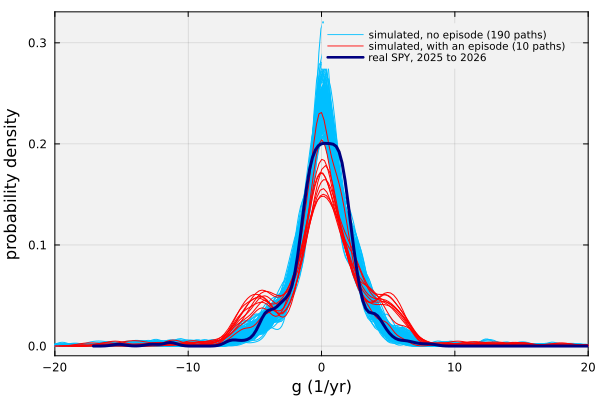

In [10]:
let

    # plot: the density of the growth rate on each path without an episode, one legend entry for the group -
    # display options used in this cell -
    # lw: Set the line width in points.
    # c: Choose the series color or, for a heatmap, the color palette.
    # label: Set the legend entry; an empty string omits that series from the legend.
    # bg: Set the plot background color.
    # background_color_outside: Set the background color outside the plotting grid.
    # framestyle: Use a box around the plotting area.
    # fg_legend: Set the legend foreground color; transparent removes its border.
    # legendfontsize: Set the legend font size in points.
    plot(bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7)
    for k ∈ eachindex(without_episode)
        label = ""; # an empty label leaves the path out of the legend
        if k == 1
            label = "simulated, no episode ($(length(without_episode)) paths)";
        end
        density!(paths_jump[:, without_episode[k]], lw = 1, c = :deepskyblue1, label = label)
    end

    # plot: the paths with an episode on top, in red -
    for k ∈ eachindex(with_episode)
        label = ""; # an empty label leaves the path out of the legend
        if k == 1
            label = "simulated, with an episode ($(length(with_episode)) paths)";
        end
        density!(paths_jump[:, with_episode[k]], lw = 1, c = :red, label = label)
    end

    # plot: the test data on top -
    density!(g, lw = 3, c = :navy, label = "real SPY, $(year(first(dates))) to $(year(last(dates)))")
    xlims!(-20, 20)
    xlabel!("g (1/yr)"); ylabel!("probability density")
end

___

## Task 2: Turn the Jump Episodes Off
In this task, we turn the jump episodes off and score both models on the same test data. We set the episode probability $\epsilon$ to zero in a copy of the model, as [Changing a fitted model](https://varnerlab.github.io/JumpHMM.jl/dev/model/#Changing-a-fitted-model) in the JumpHMM.jl documentation shows.

[The `deepcopy(...)` function](https://docs.julialang.org/en/v1/base/base/#Base.deepcopy) makes the copy, so the saved model keeps its jump episodes. With $\epsilon = 0$, no episode can start, and the chain and the emissions stay the same.

We score the copy with `JumpHMM.validate(...)`, with the same number of paths and seed, and save the results in the `report_nojump::JumpHMM.MyValidationReportModel` variable:

In [11]:
report_nojump = let

    # no jumps: set the episode probability ϵ = 0 in a copy, so no episode can start -
    nojump_model = deepcopy(model); # a copy, so the saved model stays as it is
    nojump_model.ϵ = 0.0; # ϵ = 0 per day

    # validate: the same test data, number of paths, and seed as the model with jumps -
    report = JumpHMM.validate(nojump_model, g;
        number_of_paths = number_of_paths, # number of simulated paths, each number_of_days long
        α = α, # a path passes a test when its p-value is above α
        seed = random_seed # reproduce the simulated paths
    );

    # checks: the copy has no jumps, and the saved model keeps its episodes -
    @assert nojump_model.ϵ == 0.0 "the copy should have no jump episodes"
    @assert model.ϵ > 0.0 "the saved model should keep its jump episodes"

    # return -
    report
end;

The table compares the two models, with the paths of the model with jumps split into the paths with an episode and the paths without one:

In [12]:
let

    # initialize: the groups of paths, and the report each group comes from -
    all_paths = collect(1:number_of_paths); # every simulated path of the model without jumps
    labels = ["with jumps, paths with an episode", "with jumps, paths without an episode", "no jumps, all paths"];
    groups = [with_episode, without_episode, all_paths];
    reports = [report_jump, report_jump, report_nojump];

    # one row per group: count the paths that pass each test, and add up the excess kurtosis -
    df = DataFrame(group = String[], paths = Int64[], ks = Float64[], ad = Float64[], kurt = Float64[]);
    for k ∈ eachindex(labels)
        report = reports[k];
        n = length(groups[k]); # number of paths in this group
        ks_passed = 0; # paths with a Kolmogorov–Smirnov p-value above α
        ad_passed = 0; # paths with an Anderson–Darling p-value above α
        total_kurtosis = 0.0; # sum of the excess kurtosis over the paths
        for j ∈ groups[k]
            if report.ks_pvalue[j] > α
                ks_passed += 1;
            end
            if report.ad_pvalue[j] > α
                ad_passed += 1;
            end
            total_kurtosis += report.kurtosis_sim[j];
        end
        push!(df, (labels[k], n, ks_passed / n, ad_passed / n, total_kurtosis / n)); # a group with no paths gives NaN
    end

    # let's make a pretty table -
    pretty_table(df;
        column_labels = ["", "paths", "pass rate, KS", "pass rate, AD", "excess kurtosis (mean)"], # displayed column headings
        alignment = [:l, :r, :r, :r, :r], # :l aligns a column left; :r aligns it right
        formatters = [fmt__printf("%.3f", [3, 4, 5])], # print the selected numeric columns to three decimal places
        table_format = TextTableFormat(borders = text_table_borders__compact), # text table style; borders selects the compact separator characters
        fit_table_in_display_horizontally = false # false keeps all columns instead of cropping to the display width
    );
end

 -------------------------------------- ------- --------------- --------------- ------------------------
                                         paths   pass rate, KS   pass rate, AD   excess kurtosis (mean) 
 -------------------------------------- ------- --------------- --------------- ------------------------
  with jumps, paths with an episode         10           0.100           0.100                    4.738
  with jumps, paths without an episode     190           0.958           0.984                   12.408
  no jumps, all paths                      200           0.950           0.975                   10.868
 -------------------------------------- ------- --------------- --------------- ------------------------


> __What do we see?__ The test data are short, so few paths contain an episode. The paths with an episode fail most tests. The other paths pass about as often as the paths of the model without jumps.
>
> An episode lasts many days, and each episode day is a large move from one of the most negative or most positive states. These days give the path two side bumps, and its excess kurtosis falls below that of the other paths.

___

## Task 3: Compare Volatility Clustering
In this task, we compare the volatility clustering of the test data with that of the simulated paths of the model with jumps. Volatility clustering means that large moves follow large moves, so the autocorrelation of the absolute growth rate $|g_{t}|$ on day $t$ is positive.

The 95% band for white noise is $\pm 1.96/\sqrt{T}$, where $T$ is the number of trading days in the test data. An autocorrelation inside the band is consistent with white noise. The test data cover far fewer days than the fitting period, so their band is wider.

We compute the autocorrelation of $|g_{t}|$ at lags of 1 to `number_of_lags` trading days with [the `StatsBase.autocor(...)` function](https://juliastats.org/StatsBase.jl/stable/signalcorr/#StatsBase.autocor). We save it in the `acf_test::Array{Float64,1}` variable for the test data, and in the `acf_jump::Array{Float64,2}` variable for the simulated paths, one column per path:

In [13]:
acf_test, acf_jump = let

    # checks: each lag must be shorter than the test data -
    @assert number_of_lags < number_of_days "number_of_lags must be smaller than the number of test days"

    # initialize: the lags, and the autocorrelation of |g| for the test data -
    lags = 1:number_of_lags; # trading days
    acf_test = StatsBase.autocor(abs.(g), lags);

    # the autocorrelation of |g| on each simulated path -
    acf_jump = Array{Float64,2}(undef, number_of_lags, number_of_paths); # lags × paths
    for j ∈ 1:number_of_paths
        acf_jump[:, j] = StatsBase.autocor(abs.(paths_jump[:, j]), lags); # autocorrelation of path j
    end

    # return -
    (acf_test, acf_jump)
end;

`Unhide` the code block below to see how we plotted the autocorrelation of $|g_{t}|$ for the test data and the simulated paths with [the `plot(...)` function](https://docs.juliaplots.org/stable/api/#RecipesBase.plot), the percentiles of the paths with [the `quantile(...)` function](https://docs.julialang.org/en/v1/stdlib/Statistics/#Statistics.quantile), and the 95% band for white noise with [the `hline!(...)` function](https://docs.juliaplots.org/stable/api/#Plots.hline!-Tuple). The paths with a jump episode are red.

> __What do we see?__
>
> * __Test data:__ The autocorrelation of $|g_{t}|$ is above the band at several short lags and mostly inside it at longer lags.
> * __Paths without an episode:__ Their mean autocorrelation falls inside the band after the first few lags. The chain forgets a volatile day within a few steps.
> * __Paths with an episode:__ Their mean autocorrelation stays above the band for months. At lags longer than the episode, it turns negative, because it then pairs the large moves of the episode with the small moves of ordinary days.

How long does volatility cluster in 2025 and 2026?

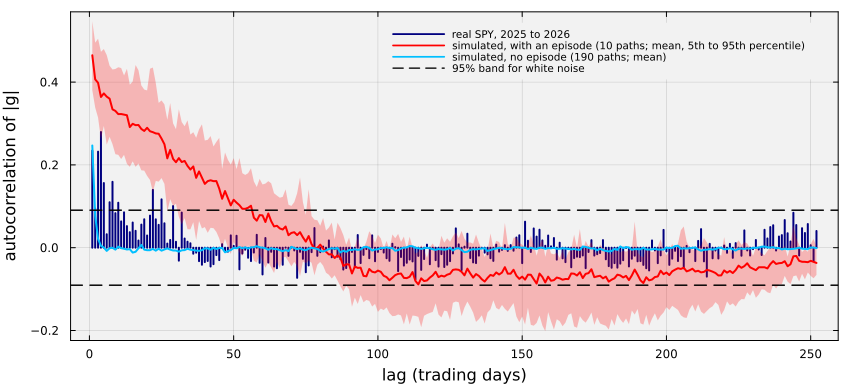

In [14]:
let

    # initialize: the lags, the 95% band, and the autocorrelations of the two groups of paths -
    lags = 1:number_of_lags; # trading days
    band = 1.96 / sqrt(number_of_days); # 95% band for the autocorrelation of white noise, T = number_of_days
    acf_with = acf_jump[:, with_episode]; # lags × paths with a jump episode
    acf_without = acf_jump[:, without_episode]; # lags × paths without one

    # the mean and the middle 90% of the paths with an episode, and the mean of the paths without one, at each lag -
    m_with = Array{Float64,1}(undef, number_of_lags); # mean over the paths with an episode
    lo_with = Array{Float64,1}(undef, number_of_lags); # 5th percentile over the paths with an episode
    hi_with = Array{Float64,1}(undef, number_of_lags); # 95th percentile over the paths with an episode
    m_without = Array{Float64,1}(undef, number_of_lags); # mean over the paths without an episode
    for k ∈ lags
        m_with[k] = mean(acf_with[k, :]);
        lo_with[k] = quantile(acf_with[k, :], 0.05);
        hi_with[k] = quantile(acf_with[k, :], 0.95);
        m_without[k] = mean(acf_without[k, :]);
    end

    # plot: the test data as sticks -
    # display options used in this cell -
    # seriestype: Draw vertical sticks from zero to each autocorrelation.
    # lw: Set the line width in points.
    # c: Choose the series color or, for a heatmap, the color palette.
    # label: Set the legend entry; an empty string omits that series from the legend.
    # bg: Set the plot background color.
    # background_color_outside: Set the background color outside the plotting grid.
    # framestyle: Use a box around the plotting area.
    # fg_legend: Set the legend foreground color; transparent removes its border.
    # legendfontsize: Set the legend font size in points.
    # size: Set the complete figure width and height in pixels.
    # left_margin: Set the left margin; Plots.mm expresses the distance in millimeters.
    # bottom_margin: Set the bottom margin; Plots.mm expresses the distance in millimeters.
    # ribbon: Give the distances below and above the mean for the shaded interval.
    # fillalpha: Set the shaded interval opacity between zero and one.
    # ls: Choose the line style; :dash draws a dashed reference line.
    plot(lags, acf_test, seriestype = :sticks, lw = 2, c = :navy, label = "real SPY, $(year(first(dates))) to $(year(last(dates)))",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7,
        size = (850, 390), left_margin = 3Plots.mm, bottom_margin = 4Plots.mm)

    # plot: the paths with an episode as a mean and its middle 90%, the paths without one as a mean, and the band -
    plot!(lags, m_with, ribbon = (m_with .- lo_with, hi_with .- m_with), lw = 2, c = :red, fillalpha = 0.25,
        label = "simulated, with an episode ($(length(with_episode)) paths; mean, 5th to 95th percentile)")
    plot!(lags, m_without, lw = 2, c = :deepskyblue1, label = "simulated, no episode ($(length(without_episode)) paths; mean)")
    hline!([band, -band], lw = 1.5, ls = :dash, c = :black, label = "95% band for white noise")
    xlabel!("lag (trading days)"); ylabel!("autocorrelation of |g|")
end

___

## Summary
In this example, we tested the jump hidden Markov model of `SPY` on the growth rates of 2025 and 2026, which came after its fitting period. We scored simulated paths against the test data, turned the jump episodes off, and compared the volatility clustering of the simulated paths with that of the data.

> __Key Takeaways:__
>
> * __The model still describes the distribution:__ We simulated paths from the model, each as long as the test data, and scored each path with the Kolmogorov–Smirnov and Anderson–Darling tests. Most paths passed both tests, although the test data had fatter tails than the average simulated path.
> * __Paths with a jump episode fail the tests:__ We turned the jump episodes off in a copy of the model and scored both models on the same data. Few paths contained an episode, and those paths failed most tests, because their episode days added side bumps to the distribution. The other paths scored like the paths of the model without jumps.
> * __Neither group of paths matches the clustering of the test data:__ We compared the autocorrelation of the absolute growth rate in the test data and in the simulated paths with the 95% band for white noise. The test data clustered at short lags. The paths without an episode forgot a volatile day within a few days, and the paths with an episode stayed clustered for months.

Knowing which features of new data the model reproduces and which it misses lets us judge what a stress test built on it can tell us.

___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success.

Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___